---
### Final version of HPK angular fits (hopefully)


1. plot the relative PDE vs angle
2. divide out the optics for known thickness, wlen
3. divide out the complete PDE for known thickness, wlen, PN paramters from other fits
4. look at this 'factored' out FF(theta) (for Vis and UV)
    * compare it with the shadowed FF

5. try fitting the FF(theta) with the shadowing + reflected function?



---

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


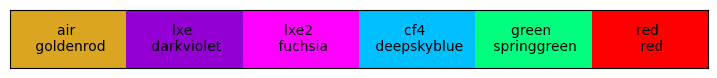

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from fittingFunctions import *
from HPK_angularTools import *

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

---
### Geometry of FF --> ff, W, H


In [2]:
FF = 0.6
pp = 50 # units of um
# FF2 = 0.7
# pp2 = 75 # units of um

## Case A
case50 = quadraticSolution(a = 1, b = -pp, c = (1-FF)*(pp**2)/4)
print("50um ppitch, ff: ", case50)
ff50 = min(case50)
print("analytic ff width:", ff50)
W50 = ff50/pp
H50 = 2./pp # 2.5um from AFM measurements

FF_theta_relative(0, 0, H50)

50um ppitch, ff:  (44.364916731037084, 5.635083268962916)
analytic ff width: 5.635083268962916


1.0

380.0
400.0
450.0
470.0
500.0
600.0
640.0
730.0
780.0
380.0
400.0
450.0
470.0
500.0
600.0
640.0
730.0
780.0
830.0
[380.0, 400.0, 450.0, 470.0, 500.0, 600.0, 640.0, 730.0, 780.0, 830.0]


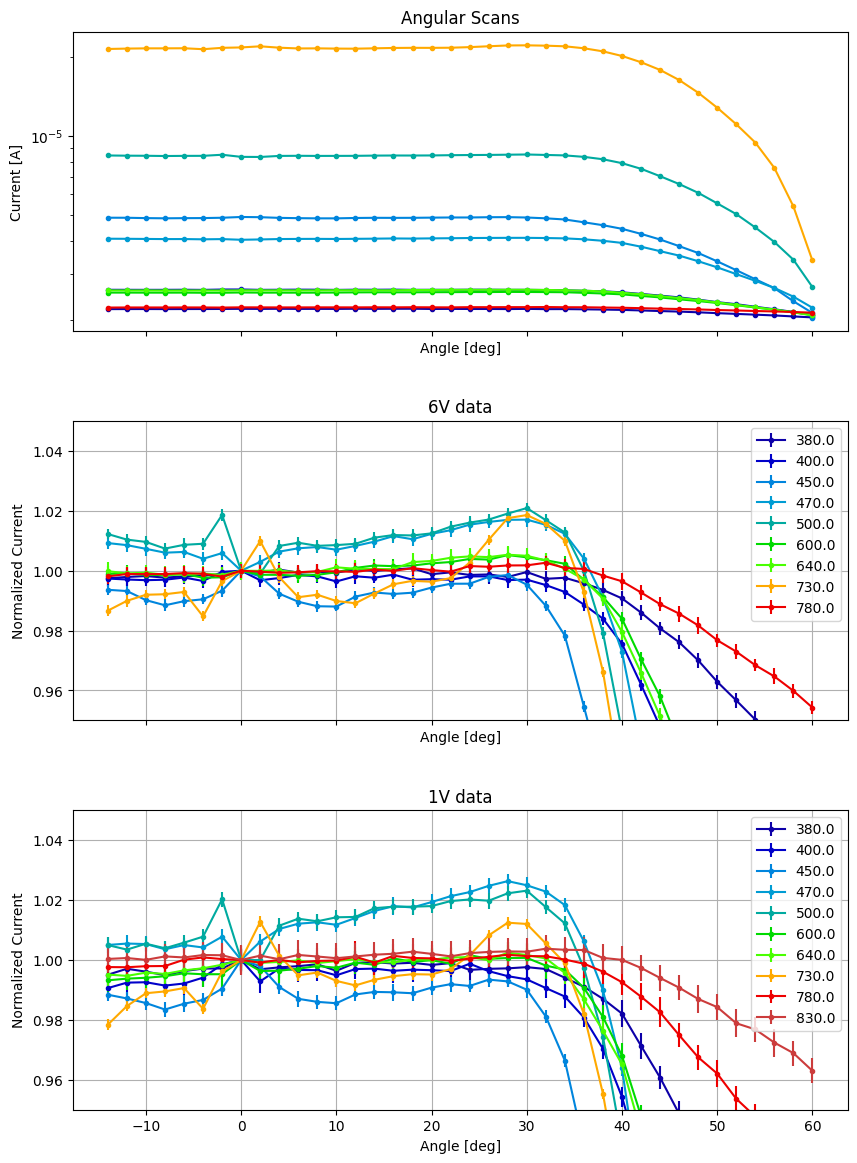

In [3]:
dataPath = os.path.join(PROPATH, "..", "veraData/HPK_angularScans_March2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
vis6V = []

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
vis1V = []

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize = (10, 14))

# 6V loop
for i, file in enumerate(sorted_f6V_list):
    if "830" in file: # skip this one, it is bad
        continue
    angData = AngularData(file)
    angData.LoadData()
    vis6V.append(angData)
    # angData.Describe()
    
    ax1.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
    
    ax2.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
aWlenList = []

# 1V loop
for i, file in enumerate(sorted_f1V_list):
    angData = AngularData(file)
    angData.LoadData()
    aWlenList.append(float(angData.wlen))
    vis1V.append(angData)
    # angData.Describe()
    
    ax3.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
print(aWlenList)

ax1.set_title("Angular Scans")
ax1.set_ylabel("Current [A]")
ax1.set_xlabel("Angle [deg]")

ax2.set_xlabel("Angle [deg]")
ax2.set_title("6V data")
ax2.set_ylabel("Normalized Current")
ax2.set_ylim(0.95, 1.05)
ax2.legend()
ax2.grid()

ax3.set_xlabel("Angle [deg]")
ax3.set_title("1V data")
ax3.set_ylabel("Normalized Current")
ax3.set_ylim(0.95, 1.05)
ax3.legend()
ax3.grid()

plt.subplots_adjust(hspace=0.3)
plt.show()

['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/../veraData/angular_scans_VUV_feb2024/HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/../veraData/angular_scans_VUV_feb2024/HPKW_angular_225nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/../veraData/angular_scans_VUV_feb2024/HPKW_angular_235nm_-110C_0.5mm_slit_6oV.csv', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/../veraData/angular_scans_VUV_feb2024/HPKW_angular_190nm_-110C_0.5mm_slit_6oV.csv']
190.0
210.0
225.0
235.0
190.0
210.0
225.0
235.0


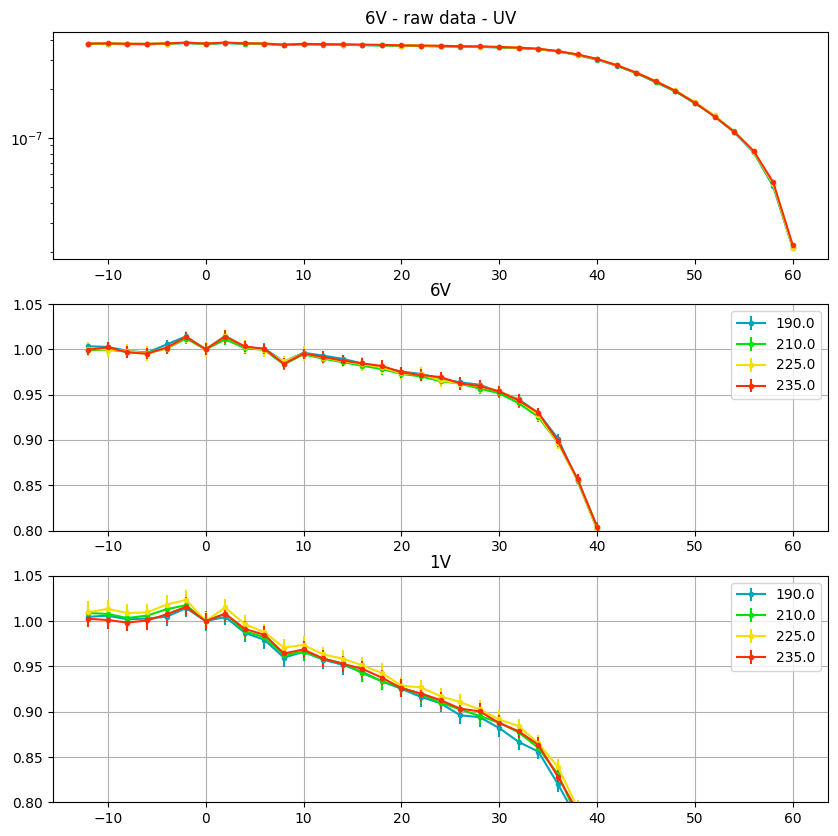

In [4]:
dataPath = os.path.join(PROPATH, "..", "veraData/angular_scans_VUV_feb2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
print(filelist_6V)
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
uv6V = []

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))
uv1V = []

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize = (10, 10))

for i, file in enumerate(sorted_f6V_list):
    angData = AngularData(file)
    angData.LoadData()
    uv6V.append(angData)
    # angData.Describe()
    
    ax1.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
    ax2.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)

ax1.set_title("6V - raw data - UV")
ax2.set_title("6V")

for i, file in enumerate(sorted_f1V_list):
    angData = AngularData(file)
    angData.LoadData()
    uv1V.append(angData)
    # angData.Describe()
    
    ax3.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
ax3.set_title("1V")

ax2.set_ylim(0.8, 1.05)


ax3.set_ylim(0.8, 1.05)
ax3.legend()

ax2.grid()
ax2.legend()
ax3.grid()
plt.show()

---
### Dividing out the optics

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


Text(0, 0.5, 'relative PDE (equation)')

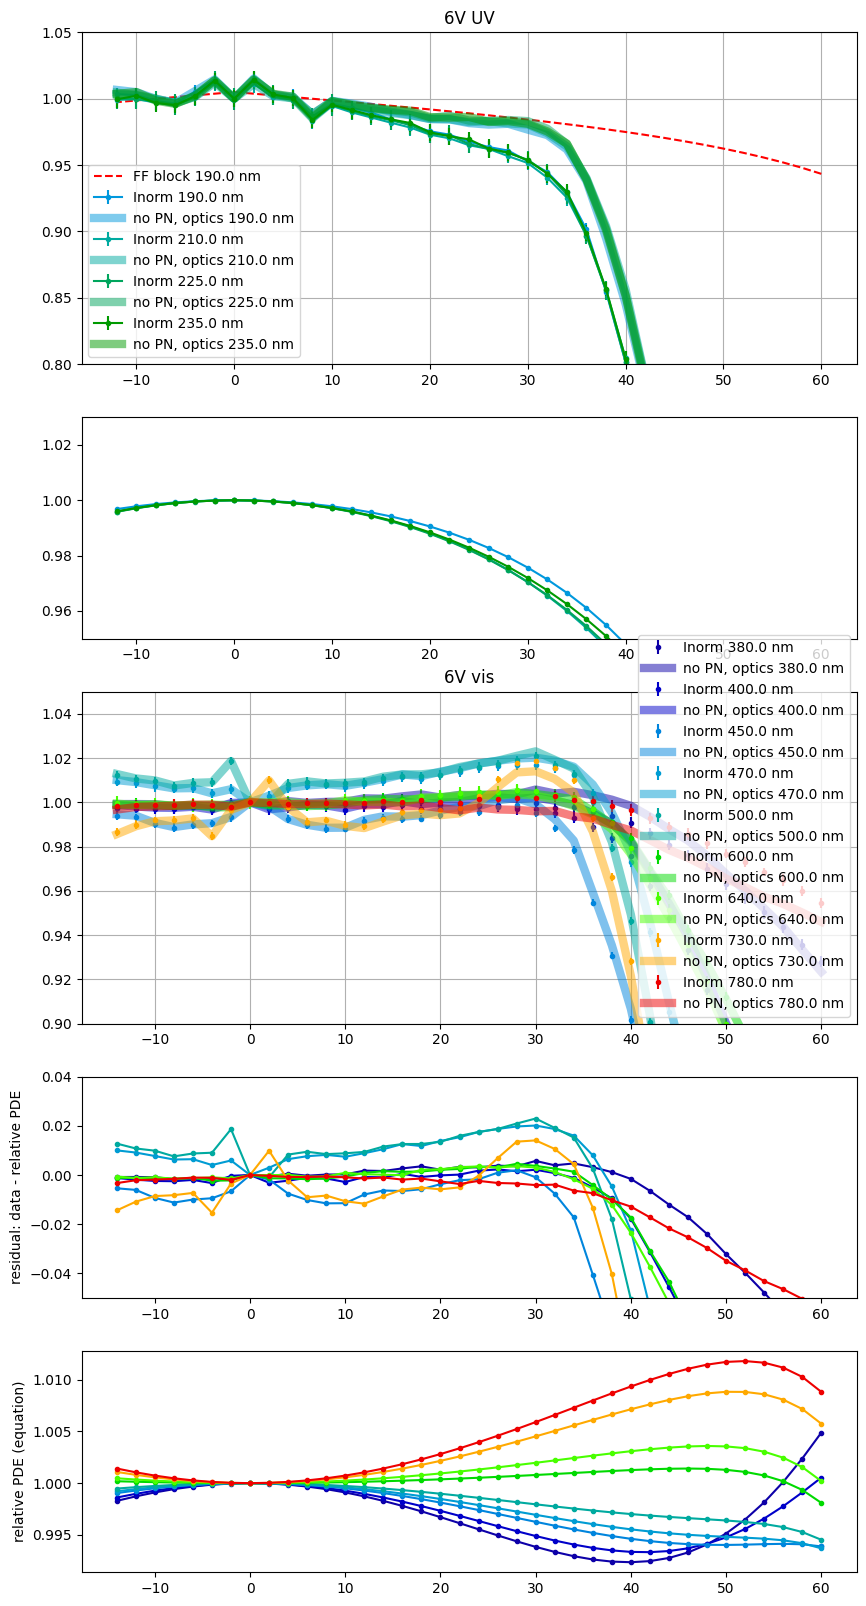

In [5]:
## UV divide it out

fig, (ax1, ax12, ax2, ax3, ax4) = plt.subplots(5, 1, figsize = (10, 20), height_ratios=[3, 2, 3, 2, 2])
to1 = 16.5 # nm
to2 = 18.5 # nm

pnArgs = {"FF":0.6, "tOxide":to1, "dp_star":1.5, "Xpn":1.2e3, "dw_star":6e3, "pe":0.95, "ph":0.35, "smoothSigma":3.7}

for i, angData in enumerate(uv6V):

    wlen = angData.wlen
    col = MS.map_value_to_hsv(wlen, 100, 400, map="nipy_spectral")
    
    trans0 = PhotonInfo(wlen = wlen, theta_1=0.).T_total_windowAndOxide(thick_oxide=to1)
    transVals1 = PhotonInfo(wlen = wlen, theta_1=angData.xRaw).T_total_windowAndOxide(thick_oxide=to1)
    transForm = transVals1/trans0
    
    yVals_noOptics = angData.Inorm/transForm
    ax1.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, marker = ".", color = col, label = f"Inorm {angData.wlen} nm")
    # ax1.errorbar(angData.xRaw, yVals_noOptics, angData.InormErr/transForm, marker = ".", color = col, label = f"No optics {angData.wlen} nm")
    
    pdeTransform = RelativePDE_angle(wlen=wlen, theta1=angData.xRaw, **pnArgs)
    yVals_noPN = angData.Inorm/pdeTransform
    ax1.errorbar(angData.xRaw, yVals_noPN, None, color = col, linestyle = "-", linewidth=6, alpha=0.5, label=f"no PN, optics {angData.wlen} nm")

    if i == 0:
        ffBlock = 0.005 + FF_theta_relative(W=W50, H=0.7/pp, theta=angData.xRaw)/FF_theta_relative(W=W50, H=H50, theta=0)
        ax1.plot(angData.xRaw, ffBlock, color = "red", linestyle = "--", label = f"FF block {angData.wlen} nm")
        
    ax12.plot(angData.xRaw, pdeTransform, marker = ".", color = col, label = f"no PN, optics {angData.wlen} nm")

ms.ResetColorCycle()
for i, angData in enumerate(vis6V):
    wlen = angData.wlen
    col = MS.map_value_to_hsv(wlen, 300, 850, map="nipy_spectral")
    
    trans0 = PhotonInfo(wlen = wlen, theta_1=0.).T_total_windowAndOxide(thick_oxide=to1)
    transVals1 = PhotonInfo(wlen = wlen, theta_1=angData.xRaw).T_total_windowAndOxide(thick_oxide=to1)
    transForm = transVals1/trans0
    
    yVals_noOptics = angData.Inorm/transForm
    
    ax2.errorbar(angData.xRaw, angData.Inorm, angData.InormErr, linestyle = "None", marker = ".", color = col, label = f"Inorm {angData.wlen} nm")
    # ax2.errorbar(angData.xRaw, yVals_noOptics, None, marker = "None", color = col, label = f"No optics {angData.wlen} nm")
    
    pdeTransform = RelativePDE_angle(wlen=wlen, theta1=angData.xRaw, **pnArgs)
    yVals_noPN = angData.Inorm/pdeTransform
    ax2.errorbar(angData.xRaw, yVals_noPN, None, linestyle = "-", color = col, linewidth=6, alpha=0.5, label=f"no PN, optics {angData.wlen} nm")
    
    #yVals_noPN is the relative FF vs angle
    residual1 = yVals_noPN - angData.Inorm
    res2 = yVals_noPN * (1 - pdeTransform) # this is equal to residual1 above
    
    res3 = angData.Inorm - pdeTransform
    trueResidual = angData.Inorm - pdeTransform
    ax3.plot(angData.xRaw, trueResidual, marker = ".", color = col, label = f"residual {angData.wlen} nm")

    ax4.plot(angData.xRaw, pdeTransform, marker = ".", color = col, label = f"no PN, optics {angData.wlen} nm")

ax1.set_title("6V UV")
ax1.set_ylim(0.8, 1.05)
ax1.legend()
ax1.grid()

ax12.set_ylim(0.95, 1.03)

ax2.set_title("6V vis")
ax2.set_ylim(0.9, 1.05)
ax2.legend()
ax2.grid()

ax3.set_ylabel("residual: data - relative PDE")
ax3.set_ylim(-0.05, 0.04)

ax4.set_ylabel("relative PDE (equation)")

---
### Fitting the UV data with the shadowing function

In [13]:
UV_FFdatatoFit_x = []
UV_FFdatatoFit_y = []
UV_FFdatatoFit_yerr = []

for i, angData in enumerate(uv6V):
    col = MS.map_value_to_hsv(wlen, 100, 400, map="nipy_spectral")

    wlen = angData.wlen
    
    trans0 = PhotonInfo(wlen = wlen, theta_1=0.).T_total_windowAndOxide(thick_oxide=to1)
    transVals1 = PhotonInfo(wlen = wlen, theta_1=angData.xRaw).T_total_windowAndOxide(thick_oxide=to1)
    transForm = transVals1/trans0

    pdeTransform = RelativePDE_angle(wlen=wlen, theta1=angData.xRaw, **pnArgs)
    yVals_noPN = angData.Inorm/pdeTransform
    yVals_error = angData.InormErr/pdeTransform
    
    # filter = (angData.xRaw < 30) & (angData.xRaw >= 0)
    filter = (angData.xRaw < 30)
    UV_FFdatatoFit_x.extend(angData.xRaw[filter])
    UV_FFdatatoFit_y.extend(yVals_noPN[filter])
    UV_FFdatatoFit_yerr.extend(yVals_error[filter])


# plotting
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 8), height_ratios=[3, 2])

# ax1.errorbar(UV_FFdatatoFit_x, UV_FFdatatoFit_y, UV_FFdatatoFit_yerr, marker = ".", linestyle = "None", color = "black", label = "data to fit")

# ax1.set_ylim(0.9, 1.05)

# doing fit
from iminuit.cost import LeastSquares
# print(dir(iminuit.cost))


least_squares_fit1 = LeastSquares(UV_FFdatatoFit_x, UV_FFdatatoFit_y, UV_FFdatatoFit_yerr, FF_theta_relative)
mUV_fit1 = Minuit(least_squares_fit1, W=0.0, H=0.01, offset = 0.015)
mUV_fit1.fixed["W"] = True

mUV_fit1.migrad()
mUV_fit1.hesse()


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 69.46 (χ²/ndof = 0.8)      │              Nfcn = 47               │
│ EDM = 8.38e-14 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ W      │    0.0    │    0.1    │            │            │         │         │  yes  │
│ 1 │ H      │  0.0257   │  0.0021   │            │            │         │         │       │
│ 2 │ offset │  0.0066   │  0.0011   │            │            │         │         │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬────────────────────────────┐
│        │        W        H   offset │
├────────┼────────────────────────────┤
│      W │        0     0e-6        0 │
│      H │     0e-6 4.41e-06   1.9e-6 │
│ offset │        0   1.9e-6 1.19e-06 │
└────────┴────────────────────────────┘

In [14]:
print("best fit normal incidence FF: ", FF_theta_relative(0, W50, mUV_fit1.values["H"], mUV_fit1.values["offset"]))
mUV_fit1.covariance.correlation()

best fit normal incidence FF:  0.6065935638219101


,W,H,offset
W,0,0,0
H,0,1,0.8
offset,0,0.8,1
